<img src="https://miro.medium.com/v2/resize:fit:1400/0*dZkodxQqSsXyB_xV.png">

In [1]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from langchain_core.messages import BaseMessage, HumanMessage
from langchain_groq import ChatGroq

In [2]:
llm = ChatGroq(
    model = "openai/gpt-oss-120b"
)

In [3]:
from langgraph.graph.message import add_messages

class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [4]:
def chat_node(state: ChatState):

    # Take user query from State
    messages = state['messages']

    # Send to LLM
    response = llm.invoke(messages)

    # Response store state
    return {'messages': [response]}

In [5]:
graph = StateGraph(ChatState)

# Add Nodes
graph.add_node('Chat Node', chat_node)

# Add Edges
graph.add_edge(START, 'Chat Node')
graph.add_edge('Chat Node', END)

chatbot = graph.compile()

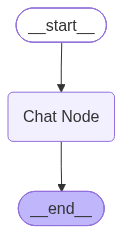

In [6]:
chatbot

In [7]:
initial_state = {
    'messages' : [HumanMessage(content = 'What are the Free LLM Models are available?')]
}

response = chatbot.invoke(initial_state)
response

{'messages': [HumanMessage(content='What are the Free LLM Models are available?', additional_kwargs={}, response_metadata={}, id='5a907931-4070-4b2c-b59b-aaa407f4f69b'),
  AIMessage(content='Below is a curated list of **free (open‑weight or free‑to‑use) large language models (LLMs)** that you can download, run locally, or call through a free tier of a hosted service.  The list is grouped by the organization that released them, with key details (model size, architecture, license, where to get it, and typical use‑cases).  I’ve also added a short note on “free‑to‑use hosted APIs” for those who prefer not to run the models themselves.\n\n---\n\n## 1️⃣ Open‑source models you can download & run yourself  \n\n| Model | Architecture | Parameter Count | License | Where to Download | Typical Strengths |\n|-------|--------------|-----------------|---------|-------------------|-------------------|\n| **GPT‑Neo** | Transformer (GPT‑2‑style) | 125M, 1.3B, 2.7B | Apache‑2.0 | Hugging Face: `EleutherA

In [8]:
while True:
    user_message = input('Type here: ')
    print('User: ', user_message)
    if user_message.strip().lower() in ['exit', 'quit', 'bye']:
        print('AI: Thanks for the Visiting!')
        break
    response = chatbot.invoke({'messages': [HumanMessage(content = user_message)]})
    print('AI: ', response['messages'][-1].content)

User:  Bye
AI: Thanks for the Visiting!


##### <i><b> Persistence in LangGraph
- Persistence in LangGraph is a built-in layer that automatically saves and restore the state of your agent or graph workflow over time.
- It works by using a checkpointer to automatically capyure snapshots of the graph's state at every step, organizing them into unique, retrievable threads.

In [9]:
from langgraph.checkpoint.memory import MemorySaver

In [10]:
checkpoint = MemorySaver()

graph = StateGraph(ChatState)

# Add Nodes
graph.add_node('Chat Node', chat_node)

# Add Edges
graph.add_edge(START, 'Chat Node')
graph.add_edge('Chat Node', END)

chatbot = graph.compile(checkpointer=checkpoint)

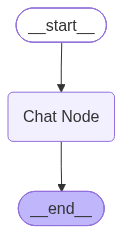

In [11]:
chatbot

In [12]:
thread_id = "1"

while True:
    user_message = input('Type here: ')
    print('User: ', user_message)
    if user_message.strip().lower() in ['exit', 'quit', 'bye']:
        print('AI: Thanks for the Visiting!')
        break

    config = {'configurable' : {'thread_id' : thread_id}}
    response = chatbot.invoke({'messages': [HumanMessage(content = user_message)]}, config = config)
    print('AI: ', response['messages'][-1].content)

User:  Bye
AI: Thanks for the Visiting!
